# 01 · Data Acquisition
**Project:** Heatwave-Conditioned Peak Electricity Demand Forecasting Using Asymmetric Loss Optimization (Title T1)

This notebook downloads every dataset the study uses, then looks at what each one contains.
All sources are **real, public and India-specific**. None needs a login.

| # | What | Who publishes it | Why we need it |
|---|------|------------------|----------------|
| A | Hourly All-India + 5 regional demand, 2019-01 to 2024-04 | Grid-India data compiled on Kaggle | the core hourly load history |
| B | Hourly All-India demand, 2024-01 to 2025-06 | NERLDC (Grid-India) + IIT Guwahati, Mendeley Data | the only hourly source for **May-Oct 2024**, the record heatwave |
| C | NLDC daily PSP reports: 15-min SCADA, 144-column daily grid ops, daily **state-wise** demand | scraped from grid-india.in, Kaggle | hourly load from Nov 2024; state demand shares |
| D | IMD gridded daily Tmax/Tmin, 1°, 1991-2025 | India Meteorological Department (Govt of India) | **official** heatwave criteria and 30-year normals |
| E | ERA5 hourly reanalysis at 33 state load centres | ECMWF/Copernicus via Open-Meteo | humidity, heat index, night-time heat, rain, sun |

> **Why several load sources?** No free dataset covers 2019-2025 hourly by itself. Stitching them (notebook 02) is the
> only way to get 7 continuous years that include the 2024 record heatwave (250 GW on 30 May 2024).

In [1]:
# --- common setup ------------------------------------------------------------
# The project code lives in src/heatwave_peak (installed with `pip install -e .`).
# If it is not installed, fall back to adding src/ to the import path.
import sys, warnings
from pathlib import Path
try:
    import heatwave_peak
except ImportError:
    sys.path.insert(0, str(Path.cwd().parent / "src"))
    import heatwave_peak
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from heatwave_peak import config as C

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

def savefig(name):
    """Save the current figure to reports/figures/<name>.png."""
    plt.savefig(C.FIGURES_DIR / f"{name}.png", bbox_inches="tight", dpi=130)

## 1. Download (idempotent)
Each function skips files that already exist, so re-running this cell is cheap. The first full download takes
~15-20 minutes. Most of that is ERA5, because the free Open-Meteo tier is rate-limited and we pause between states.

In [2]:
from heatwave_peak import data_download as DL
DL.write_state_reference_table()
DL.download_load_datasets()
DL.download_imd_gridded()     # 35 years x {tmax, tmin} binary .GRD files
DL.download_era5_hourly()     # 33 CSVs, one per state

[skip] shubhamvashisht/hourly-load-india-electrical-load-forecasting: already present in C:\Users\soumya\Documents\VIT-LABS\ml-project\data\raw\load\kaggle_hourly_load_india
[skip] halcyonvector/india-power-grid-nldc-daily-psp-reports: already present in C:\Users\soumya\Documents\VIT-LABS\ml-project\data\raw\load\nldc_psp_reports
[skip] Mendeley bridge file present: January 2024- June 2025.xlsx
[ok  ] IMD tmax: 35 yearly files
[ok  ] IMD tmin: 35 yearly files


## 2. Inventory of the raw folder

In [3]:
rows = []
for f in sorted(C.RAW_DIR.rglob("*")):
    if f.is_file():
        rows.append({"folder": str(f.parent.relative_to(C.RAW_DIR)), "file": f.name,
                     "size_MB": round(f.stat().st_size / 1e6, 2)})
inv = pd.DataFrame(rows)
print(f"{len(inv)} raw files, {inv.size_MB.sum():.0f} MB in total")
inv.groupby("folder").agg(n_files=("file", "size"), size_MB=("size_MB", "sum")).round(1)

113 raw files, 397 MB in total


,n_files,size_MB
folder,,
load\kaggle_hourly_load_india,2,3.3
load\mendeley_nerldc_hourly,1,0.7
load\nldc_psp_reports,6,115.1
reference,1,0.0
weather\era5_openmeteo_hourly,33,179.6
weather\imd_gridded\tmax,35,49.1
weather\imd_gridded\tmin,35,49.1


## 3. A - Kaggle hourly load (Grid-India)

In [4]:
from heatwave_peak import load_processing as LP
a = LP.read_kaggle_hourly()
print(a.shape, a.index.min(), "->", a.index.max())
a.head()

(46728, 6) 2019-01-01 00:00:00 -> 2024-04-30 23:00:00


,national_mw,NR,WR,ER,SR,NER
datetime,,,,,,
2019-01-01 00:00:00,118690.67,33692.02,38522.22,13128.89,31681.83,1665.72
2019-01-01 01:00:00,116029.23,32534.39,38071.09,12737.53,31129.97,1556.24
2019-01-01 02:00:00,114044.14,31730.37,37680.10,12387.36,30760.87,1485.44
2019-01-01 03:00:00,113648.97,31529.25,37747.37,12301.12,30616.27,1454.96
2019-01-01 04:00:00,116290.05,32406.61,38101.80,12479.13,31839.38,1463.14


In [5]:
# The national column equals the sum of the five regions (to within rounding).
# That is a good integrity check of the source.
(a["national_mw"] - a[["NR", "WR", "SR", "ER", "NER"]].sum(axis=1)).abs().describe()

count    4.672800e+04
mean     4.668721e-03
std      5.306276e-03
min      0.000000e+00
25%      0.000000e+00
50%      2.910383e-11
75%      1.000000e-02
max      2.000000e-02
dtype: float64

## 4. B - Mendeley NERLDC hourly All-India demand

In [6]:
b = LP.read_mendeley_hourly()
print(len(b), b.index.min(), "->", b.index.max())
b.head()

12984 2024-01-01 00:00:00 -> 2025-06-24 23:00:00


Timestamp
2024-01-01 00:00:00    141981.26
2024-01-01 01:00:00    138675.49
2024-01-01 02:00:00    136122.78
2024-01-01 03:00:00    135806.51
2024-01-01 04:00:00    139905.77
Name: national_mw, dtype: float64

## 5. C - NLDC Power Supply Position (PSP) reports
`study1_hourly.csv` has **46,728 rows x 151 columns**: hourly load joined with 144 daily grid-operation columns
(generation by fuel, outages, inter-regional flows, frequency statistics). `study3_states.csv` has the **daily maximum demand met by each state**.
We use it to weight each state's weather by how much electricity that state actually consumes.

In [7]:
psp_hourly_cols = pd.read_csv(C.RAW_PSP_DIR / "study1_hourly.csv", nrows=2).columns
print("study1_hourly columns:", len(psp_hourly_cols))
psp = LP.read_psp_daily()
print("study1_daily:", psp.shape, psp.index.min().date(), "->", psp.index.max().date())
psp[["max_demand_met_total_mw", "energy_met_total_mu", "solar_gen_total_mu", "share_res_pct",
     "energy_shortage_total_mu"]].describe().round(1)

study1_hourly columns: 151
study1_daily: (2761, 143) 2018-12-31 -> 2026-09-29


,max_demand_met_total_mw,energy_met_total_mu,solar_gen_total_mu,share_res_pct,energy_shortage_total_mu
count,2756.0,2758.0,2758.0,2760.0,2757.0
mean,193066.1,4192.1,284.6,12.0,9.5
std,28749.3,632.7,144.2,3.6,14.1
min,0.0,2592.0,66.0,3.1,0.0
25%,169599.8,3706.0,162.0,9.5,1.3
50%,192887.5,4160.3,260.7,11.4,6.4
75%,214948.2,4662.2,371.3,14.1,12.8
max,270820.0,6002.3,696.4,96.8,214.1


In [8]:
st = pd.read_csv(C.RAW_PSP_DIR / "study3_states.csv", parse_dates=["date"])
print(st.shape)
st.groupby(["region", "state"]).max_demand_met_mw.mean().round(0).sort_values(ascending=False).head(15)

(102464, 10)


region  state         
WR      Maharashtra       23987.0
NR      UP                20382.0
WR      Gujarat           18430.0
SR      Tamil Nadu        15563.0
NR      Rajasthan         13457.0
WR      MP                12356.0
SR      Karnataka         12255.0
        Telangana         11119.0
        Andhra Pradesh    10025.0
NR      Punjab             9219.0
        Haryana            8424.0
ER      West Bengal        8423.0
        Bihar              5726.0
        Odisha             5232.0
NR      Delhi              4945.0
Name: max_demand_met_mw, dtype: float64

In [9]:
scada = pd.read_csv(C.RAW_PSP_DIR / "study2_scada.csv", usecols=["date", "time", "demand_met_mw", "solar_mw", "wind_mw"])
print("15-min SCADA rows:", len(scada), scada.date.min(), "->", scada.date.max())
scada.head()

15-min SCADA rows: 64860 2024-11-04 -> 2026-09-29


,date,time,demand_met_mw,wind_mw,solar_mw
0,2024-11-04,00:00,151130.61,2622.0,163.0
1,2024-11-04,00:15,150520.82,2529.0,163.0
2,2024-11-04,00:30,149521.81,2433.0,163.0
3,2024-11-04,00:45,148660.83,2369.0,163.0
4,2024-11-04,01:00,147593.82,2473.0,163.0


## 6. D - IMD gridded temperature (Government of India)
IMD's 1° gridded Tmax/Tmin (Srivastava et al., 2009) interpolates ~395 quality-controlled stations. IMD uses this
product for its own heatwave climatology, so heatwave labels built on it follow the **official** definition.

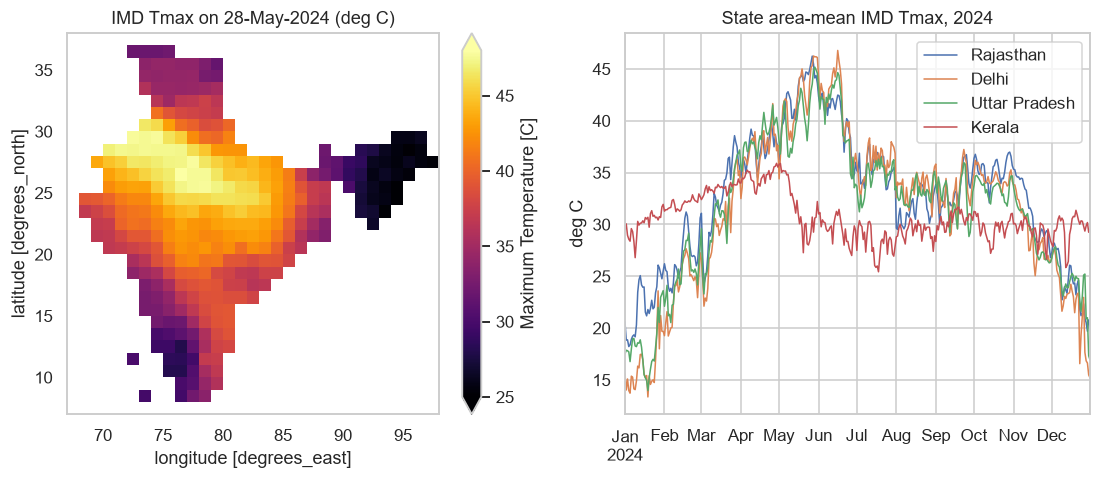

In [10]:
import imdlib as imd
tmax = imd.open_data("tmax", 2024, 2024, "yearwise", file_dir=str(C.RAW_IMD_DIR))
xr_ = tmax.get_xarray()
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
xr_["tmax"].sel(time="2024-05-28").where(xr_["tmax"].sel(time="2024-05-28") < 99).plot(ax=ax[0], cmap="inferno", vmin=25, vmax=48)
ax[0].set_title("IMD Tmax on 28-May-2024 (deg C)")
tmax.region(state=["Rajasthan", "Delhi", "Uttar Pradesh", "Kerala"]).plot(ax=ax[1], lw=1)
ax[1].set_title("State area-mean IMD Tmax, 2024"); ax[1].set_ylabel("deg C")
savefig("01_imd_tmax_2024"); plt.show()

## 7. E - ERA5 hourly weather at state load centres

per-state hourly rows: 62112 | columns: ['datetime', 'state', 'grid_lat', 'grid_lon', 'elevation_m', 'temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'apparent_temperature', 'precipitation', 'cloud_cover', 'shortwave_radiation', 'wind_speed_10m']
total ERA5 hourly rows: 2049696


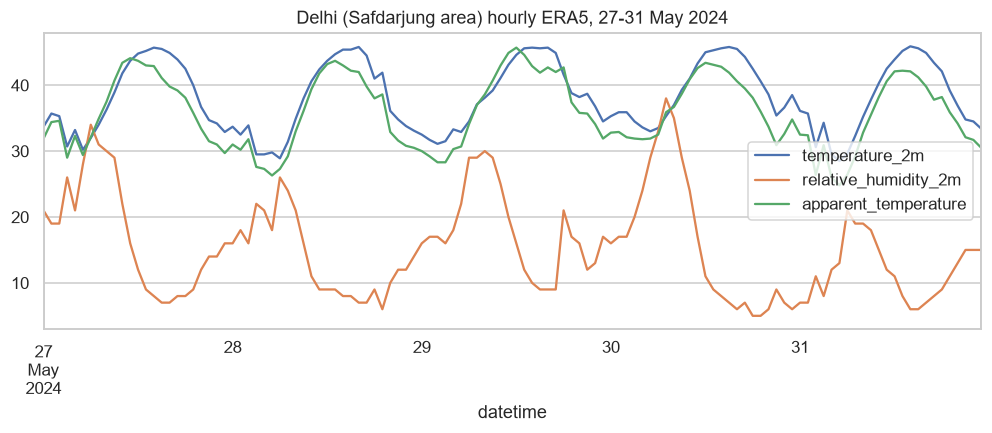

,state,nldc_names,grid_region,load_centre,lat,lon
0,Delhi,Delhi,NR,New Delhi,28.61,77.21
1,Haryana,Haryana,NR,Rohtak,28.89,76.61
2,Punjab,Punjab,NR,Ludhiana,30.90,75.85
3,Rajasthan,Rajasthan,NR,Jaipur,26.91,75.79
4,Uttar Pradesh,UP,NR,Lucknow,26.85,80.95
5,Uttarakhand,Uttarakhand,NR,Dehradun,30.32,78.03
6,Himachal Pradesh,HP,NR,Shimla,31.10,77.17
7,Jammu and Kashmir,J&K(UT) & Ladakh(UT),NR,Jammu,32.73,74.86
8,Chandigarh,Chandigarh,NR,Chandigarh,30.73,76.78
9,Gujarat,Gujarat,WR,Ahmedabad,23.02,72.57


In [11]:
ref = pd.read_csv(C.RAW_REFERENCE_DIR / "state_metadata.csv")
e = pd.read_csv(C.RAW_ERA5_DIR / "era5_hourly_Delhi.csv", parse_dates=["datetime"])
print("per-state hourly rows:", len(e), "| columns:", list(e.columns))
print("total ERA5 hourly rows:", len(e) * len(ref))
e.set_index("datetime").loc["2024-05-27":"2024-05-31", ["temperature_2m", "relative_humidity_2m", "apparent_temperature"]].plot(figsize=(11, 3.5))
plt.title("Delhi (Safdarjung area) hourly ERA5, 27-31 May 2024"); savefig("01_era5_delhi_may2024"); plt.show()
ref

### Summary
* **Load:** about 61,000 hourly All-India rows (2019-2025) after stitching A + B + C, 46,728 hourly regional rows,
  ~100,000 state-day demand rows, and 144-column daily grid-operation records.
* **Weather:** 33 states x 35 years of IMD daily Tmax/Tmin, and about 2 million hourly ERA5 rows x 8 variables.

Next: **02** cleans and stitches the load data and extracts the daily peak.